# 03 - Transfer Learning
---
 Corre em **GPU**. 
 EfficientNetB0 e ResNet50, cada uma em duas fases (feature extraction + fine-tuning), reconstruindo os conjuntos a partir de `split_indices.npz`.


In [1]:
# Importacoes -- Transfer Learning (GPU).
import os, random, pickle, sys
from itertools import product
from pathlib import Path
import numpy as np
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.applications import EfficientNetB0, ResNet50
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, recall_score


In [2]:
# Google colab check: Bootstrap - deteta Colab vs local, monta o Drive se necessario e coloca o repo
# no sys.path. 
try:
    import google.colab  # noqa: F401
    from google.colab import drive
    drive.mount('/content/drive')
    REPO_ROOT = Path('/content/drive/MyDrive/ophthalmic-referral-cnn')
except ImportError:
    REPO_ROOT = Path.cwd()
    while not (REPO_ROOT / 'src').is_dir():
        if REPO_ROOT.parent == REPO_ROOT:
            raise RuntimeError("Repo root not found — no 'src' directory above cwd")
        REPO_ROOT = REPO_ROOT.parent

sys.path.insert(0, str(REPO_ROOT))

from src import bootstrap, data, viz

IN_COLAB = bootstrap.setup()
REPO_DIR = bootstrap.get_repo_dir(IN_COLAB)
DATA_DIR = REPO_ROOT
print("DATA_DIR:", DATA_DIR)
print("contents:", os.listdir(DATA_DIR))
base_dir = str(DATA_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA_DIR: /content/drive/MyDrive/ophthalmic-referral-cnn
contents: ['Deep_Learning_Base.ipynb', 'notebooks', 'src', 'ocular', 'artifacts']


In [3]:
# Reprodutibilidade: sementes fixas em todas as fontes de aleatoriedade.
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)


In [4]:
# Carregamento do dataset (mesma ordem determinista de src/data.py).
X_original, y, nomes_ficheiros, labels_ficheiros, folders = data.load_dataset(DATA_DIR)
print("X_original:", X_original.shape, "| y:", y.shape)


X_original: (2570, 224, 224, 3) | y: (2570,)


In [7]:
# Diretorios de artefactos -- sempre em Drive (derivam de REPO_DIR).
ARTIFACT_DIRS = bootstrap.get_artifact_dirs(REPO_DIR)
ARTIFACTS_DIR = ARTIFACT_DIRS["artifacts"]
MODELS_DIR    = ARTIFACT_DIRS["models"]
PREDS_DIR     = ARTIFACT_DIRS["preds"]
HISTORY_DIR   = ARTIFACT_DIRS["history"]
for _d in (MODELS_DIR, PREDS_DIR, HISTORY_DIR):
    _d.mkdir(parents=True, exist_ok=True)
print("Artefactos em:", ARTIFACTS_DIR)


Artefactos em: /content/drive/MyDrive/ophthalmic-referral-cnn/artifacts


In [8]:
# Reconstrucao dos indices do split. 
# Transfer learning usa pixels em [0,255]; cada base aplica o seu proprio pre-processamento interno.
split = data.load_split_indices(ARTIFACTS_DIR / "split_indices.npz")
trainval_idx, test_idx = split["trainval_idx"], split["test_idx"]
train_idx, val_idx = split["train_idx"], split["val_idx"]
y = y.astype(int)
y_test = y[test_idx]
class_names = data.CLASS_NAMES


In [9]:
# Split para Transfer Learning (pixels em [0, 255] — sem normalização prévia)
# Reutiliza os mesmos índices da secção 3.1 

X_train_tl = X_original[train_idx].astype("float32")
X_val_tl   = X_original[val_idx].astype("float32")
y_train_tl = y[train_idx]
y_val_tl   = y[val_idx]
X_test_tl  = X_original[test_idx].astype("float32")

print(f"Treino: {X_train_tl.shape}  min={X_train_tl.min():.1f}  max={X_train_tl.max():.1f}")
print(f"Val:    {X_val_tl.shape}")
print(f"Teste:  {X_test_tl.shape}")

Treino: (1541, 224, 224, 3)  min=0.0  max=255.0
Val:    (522, 224, 224, 3)
Teste:  (507, 224, 224, 3)


In [10]:
# Pesos de classe (identicos aos das CNNs: mesma particao de treino).
classes = np.unique(y_train_tl)
pesos = compute_class_weight(class_weight="balanced", classes=classes, y=y_train_tl)
class_weight = {int(c): float(w) for c, w in zip(classes, pesos)}
print("Pesos por classe:", class_weight)


Pesos por classe: {0: 2.131396957123098, 1: 0.7854230377166157, 2: 0.7951496388028896}


### Registo centralizado de modelos treinados para avaliação comparativa.
As previsões são calculadas e CONGELADAS no momento do registo, que ocorre sempre imediatamente a seguir ao treino do próprio modelo, garantido que não existem problemas de referenciação a modelos já treinados.

In [10]:

modelos_treinados = []


def adicionar_modelo(nome, modelo, history, X_teste, X_treino=None, y_treino=None):
    global modelos_treinados
    X_tr = X_treino if X_treino is not None else X_train
    y_tr = y_treino if y_treino is not None else y_train

    # Congelar as previsões AGORA, enquanto o modelo está no estado que este
    # nome descreve. Depois disto, mutações do objeto já não afectam a tabela.
    proba_teste = modelo.predict(X_teste, verbose=0)
    proba_treino = modelo.predict(X_tr, verbose=0)

    # Guarda contra aliasing: dois modelos distintos não produzem previsões
    # bit-a-bit idênticas em 507x3 floats. Se isto disparar, duas entradas
    # estão a partilhar o mesmo objeto.
    for outro_nome, _, _, _, _, _, outra_proba, _ in modelos_treinados:
        if outra_proba.shape == proba_teste.shape and np.array_equal(outra_proba, proba_teste):
            raise RuntimeError(
                f"ALIASING: '{nome}' produz previsões idênticas a '{outro_nome}'. "
                "Provavelmente é o mesmo objeto de modelo registado duas vezes "
                "(ex.: fine-tuning aplicado in place ao modelo de feature extraction). "
                "Cada condição precisa da sua própria instância."
            )

    caminho = PREDS_DIR / f"{data.slug(nome)}_proba.npy"
    np.save(caminho, proba_teste)
    np.save(PREDS_DIR / f"{data.slug(nome)}_train_proba.npy", proba_treino)

    with open(HISTORY_DIR / f"{data.slug(nome)}.pkl", "wb") as f:
        pickle.dump(history.history, f)

    data.guardar_modelo(nome, MODELS_DIR, modelo)

    # remover entrada anterior com o mesmo nome (evita duplicados ao re-correr)
    modelos_treinados = [m for m in modelos_treinados if m[0] != nome]
    modelos_treinados.append((
        nome, modelo, history, X_teste, X_tr, y_tr, proba_teste, proba_treino,
    ))
    print(f"Adicionado: {nome}  (total: {len(modelos_treinados)})  -> {caminho.name}")


## 3.1 EfficientNetB0
---
O **EfficientNetB0** é a variante base da família EfficientNet, uma arquitetura que
escala as dimensões da rede (profundidade, largura e resolução) de forma composta e
controlada, obtendo melhor desempenho com menos parâmetros do que arquiteturas
tradicionais como VGG ou ResNet.

É amplamente utilizado em tarefas de classificação de imagens médicas pela sua
eficiência computacional e pela qualidade das representações aprendidas no ImageNet,
que transferem bem para domínios especializados com datasets de dimensão limitada.

In [11]:
# EfficientNetB0 — Feature Extraction
# Base convolucional congelada: apenas a cabeça de classificação é treinada.
# O pré-processamento da EfficientNetB0 é aplicado internamente pela própria base.

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
base_model.trainable = False  # congelar todos os pesos pré-treinados

inputs  = tf.keras.Input(shape=(224, 224, 3))
x       = base_model(inputs, training=False)
x       = tf.keras.layers.GlobalAveragePooling2D()(x)
x       = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(3, activation="softmax")(x)

model_effnet = Model(inputs, outputs)

model_effnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

es = EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)

nome_effnet_fe = "EfficientNetB0 (feature extraction)"
checkpoint_effnet_fe = ModelCheckpoint(
    filepath=str(MODELS_DIR / f"{data.slug(nome_effnet_fe)}.keras"),
    monitor="val_loss",
    save_best_only=True,
)

history_effnet_phase1 = model_effnet.fit(
    X_train_tl, y_train_tl,
    validation_data=(X_val_tl, y_val_tl),
    epochs=15,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[es, checkpoint_effnet_fe],
    verbose=2
)
adicionar_modelo(nome_effnet_fe, model_effnet, history_effnet_phase1, X_test_tl, X_train_tl, y_train_tl)

Epoch 1/15
49/49 - 26s - 526ms/step - accuracy: 0.6755 - loss: 0.7032 - val_accuracy: 0.8602 - val_loss: 0.4657
Epoch 2/15
49/49 - 6s - 120ms/step - accuracy: 0.8131 - loss: 0.4394 - val_accuracy: 0.8985 - val_loss: 0.3622
Epoch 3/15
49/49 - 6s - 116ms/step - accuracy: 0.8559 - loss: 0.3534 - val_accuracy: 0.9119 - val_loss: 0.3103
Epoch 4/15
49/49 - 6s - 123ms/step - accuracy: 0.8812 - loss: 0.3234 - val_accuracy: 0.9234 - val_loss: 0.2787
Epoch 5/15
49/49 - 6s - 116ms/step - accuracy: 0.9007 - loss: 0.2913 - val_accuracy: 0.9330 - val_loss: 0.2462
Epoch 6/15
49/49 - 6s - 125ms/step - accuracy: 0.9124 - loss: 0.2691 - val_accuracy: 0.9406 - val_loss: 0.2260
Epoch 7/15
49/49 - 6s - 119ms/step - accuracy: 0.9182 - loss: 0.2592 - val_accuracy: 0.9444 - val_loss: 0.2163
Epoch 8/15
49/49 - 6s - 120ms/step - accuracy: 0.9234 - loss: 0.2364 - val_accuracy: 0.9483 - val_loss: 0.2035
Epoch 9/15
49/49 - 6s - 126ms/step - accuracy: 0.9299 - loss: 0.2338 - val_accuracy: 0.9464 - val_loss: 0.1945


Última train accuracy: 0.9415963888168335
Última val accuracy:   0.959770143032074
Melhor train accuracy: 0.9415963888168335
Melhor val accuracy:   0.959770143032074


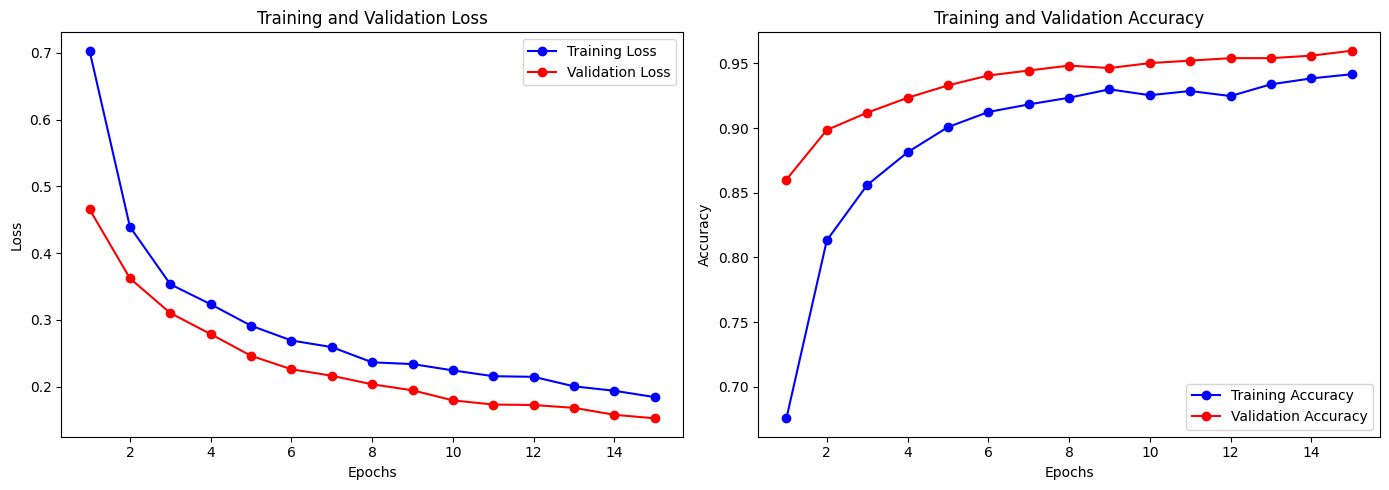

In [12]:
# Curvas de treino/validacao (usa o history vivo deste fit).
viz.plot_training_history(history_effnet_phase1)


### 3.2 EfficientNetB0 - Fine-Tuning

Partindo dos pesos obtidos na fase de Feature Extraction, procedemos ao Fine-Tuning
da EfficientNetB0. As últimas camadas da base convolucional foram descongeladas e
re-treinadas com um *learning rate* muito mais baixo, de forma a ajustar as
representações de alto nível ao domínio específico das imagens oftalmológicas sem
corromper os pesos pré-treinados.

O *grid search* explorou 9 combinações de *learning rate* ∈ {1e-4, 1e-5, 1e-6} e
número de camadas descongeladas ∈ {10, 30, 50}, avaliadas pelo **F1-macro** na
validação. A melhor combinação encontrada foi **LR=1e-4** com **50 camadas
descongeladas** (F1=0.9682), sugerindo que um ajuste mais profundo da rede beneficia
a adaptação ao domínio oftalmológico.


In [13]:

def fine_tuning_grid_search(model, base_model, nome_modelo, phase1_weights):
    """
    Grid search sobre learning_rate e n_layers_unfrozen para fine-tuning.
    Para cada combinação, parte sempre dos pesos da fase 1 (feature extraction)
    para garantir comparação justa. Seleciona com base no F1-macro na validação.
    """
    learning_rates = [1e-4, 1e-5, 1e-6]
    n_layers_list  = [10, 30, 50]

    resultados = []

    for lr, n_layers in product(learning_rates, n_layers_list):
        tf.keras.utils.set_random_seed(SEED)
        print(f"=== {nome_modelo} | LR={lr}  layers={n_layers} ===")

        # restaurar pesos da fase 1 para partir do mesmo ponto em cada iteração
        model.set_weights(phase1_weights)

        # descongelar apenas as últimas n_layers da base convolucional
        base_model.trainable = True
        for layer in base_model.layers[:-n_layers]:
            layer.trainable = False

        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        es = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

        model.fit(
            X_train_tl, y_train_tl,
            validation_data=(X_val_tl, y_val_tl),
            epochs=10,
            batch_size=32,
            class_weight=class_weight,
            callbacks=[es],
            verbose=0
        )

        # avaliar na validação — critério de selecção: F1-macro
        y_pred  = np.argmax(model.predict(X_val_tl, verbose=0), axis=1)
        f1m     = f1_score(y_val_tl, y_pred, average="macro")
        rec_cat = recall_score(y_val_tl, y_pred, labels=[0], average="macro")

        resultados.append({
            "lr": lr, "n_layers": n_layers,
            "f1_macro": float(f1m), "recall_catarata": float(rec_cat)
        })
        print(f"   F1-macro={f1m:.4f}  recall_catarata={rec_cat:.4f}")

        # congelar novamente antes da próxima iteração
        base_model.trainable = False

    # ordenar por F1-macro e mostrar ranking completo
    resultados.sort(key=lambda r: r["f1_macro"], reverse=True)
    print(f"\n===== RANKING — {nome_modelo} =====")
    for r in resultados:
        print(f"F1={r['f1_macro']:.4f}  rec_cat={r['recall_catarata']:.4f}  <-  LR={r['lr']}  layers={r['n_layers']}")

    return resultados[0]  # devolver os melhores hiperparâmetros

In [14]:
def aplicar_melhor_fine_tuning(model, base_model, best_params, nome_modelo, phase1_weights):
    """
    Treina o modelo final com os melhores hiperparâmetros encontrados no grid search.
    Restaura os pesos da fase 1, descongela as últimas n_layers e treina com LR reduzido.
    """
    # restaurar pesos da feature extraction para partir do mesmo ponto
    model.set_weights(phase1_weights)

    # descongelar apenas as últimas n_layers da base
    base_model.trainable = True
    for layer in base_model.layers[:-best_params["n_layers"]]:
        layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=best_params["lr"]),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

    nome_final = f"{nome_modelo} (fine-tuned)"
    checkpoint = ModelCheckpoint(
        filepath=str(MODELS_DIR / f"{data.slug(nome_final)}.keras"),
        monitor="val_loss",
        save_best_only=True,
    )

    history = model.fit(
        X_train_tl, y_train_tl,
        validation_data=(X_val_tl, y_val_tl),
        epochs=20,
        batch_size=32,
        class_weight=class_weight,
        callbacks=[es, checkpoint],
        verbose=2
    )

    adicionar_modelo(nome_final, model, history, X_test_tl, X_train_tl, y_train_tl)
    return history

In [15]:
# EfficientNetB0 — Fine-Tuning
# Guardar pesos da fase 1 antes de descongelar camadas.
# O grid search selecciona o melhor LR e número de camadas a descongelar.

phase1_weights_effnet = model_effnet.get_weights()

best_effnet = fine_tuning_grid_search(
    model_effnet, base_model,
    "EfficientNetB0",
    phase1_weights_effnet
    )
history_effnet_ft = aplicar_melhor_fine_tuning(
    model_effnet,
    base_model,
    best_effnet,
    "EfficientNetB0",
    phase1_weights_effnet
    )

=== EfficientNetB0 | LR=0.0001  layers=10 ===
   F1-macro=0.9652  recall_catarata=0.9733
=== EfficientNetB0 | LR=0.0001  layers=30 ===
   F1-macro=0.9680  recall_catarata=0.9733
=== EfficientNetB0 | LR=0.0001  layers=50 ===
   F1-macro=0.9682  recall_catarata=0.9733
=== EfficientNetB0 | LR=1e-05  layers=10 ===
   F1-macro=0.9475  recall_catarata=0.9733
=== EfficientNetB0 | LR=1e-05  layers=30 ===
   F1-macro=0.9445  recall_catarata=0.9600
=== EfficientNetB0 | LR=1e-05  layers=50 ===
   F1-macro=0.9582  recall_catarata=0.9600
=== EfficientNetB0 | LR=1e-06  layers=10 ===
   F1-macro=0.9289  recall_catarata=0.9733
=== EfficientNetB0 | LR=1e-06  layers=30 ===
   F1-macro=0.8731  recall_catarata=0.9600
=== EfficientNetB0 | LR=1e-06  layers=50 ===
   F1-macro=0.8675  recall_catarata=0.9600

===== RANKING — EfficientNetB0 =====
F1=0.9682  rec_cat=0.9733  <-  LR=0.0001  layers=50
F1=0.9680  rec_cat=0.9733  <-  LR=0.0001  layers=30
F1=0.9652  rec_cat=0.9733  <-  LR=0.0001  layers=10
F1=0.9582  

Última train accuracy: 0.9993510842323303
Última val accuracy:   0.9808428883552551
Melhor train accuracy: 0.9993510842323303
Melhor val accuracy:   0.984674334526062


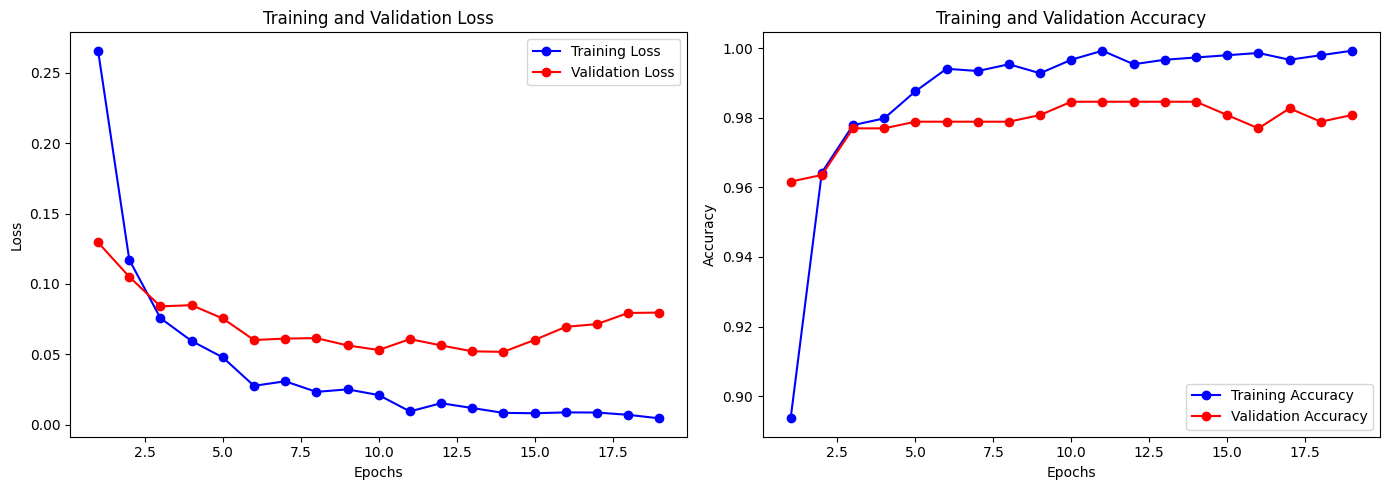

In [16]:
# Curvas de treino/validacao (usa o history vivo deste fit).
viz.plot_training_history(history_effnet_ft)


## 3.3 ResNet50

A **ResNet50** (Residual Network) é uma arquitetura de 50 camadas que introduziu as
**ligações residuais** (*skip connections*): atalhos que permitem ao gradiente fluir
diretamente entre camadas não adjacentes, resolvendo o problema de degradação do
treino em redes muito profundas. É uma das arquiteturas mais utilizadas em visão
computacional e um benchmark comum em classificação de imagens médicas.

Ao contrário do EfficientNetB0, a ResNet50 requer um pré-processamento específico
(*mean subtraction* por canal RGB), aplicado internamente no modelo.

In [ ]:
# ResNet50 — Feature Extraction
# Base convolucional congelada: apenas a cabeça de classificação é treinada.
# O pré-processamento específico da ResNet (mean subtraction por canal RGB)
# é aplicado internamente via Lambda layer.

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

base_model_resnet = ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
base_model_resnet.trainable = False  # congelar todos os pesos pré-treinados

inputs = tf.keras.Input(shape=(224, 224, 3))
x = tf.keras.layers.Lambda(
    data.resnet50_preprocess,
    output_shape=(224, 224, 3),
    name="resnet50_preprocess",
)(inputs)  # pré-processamento interno da ResNet
x = base_model_resnet(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(3, activation="softmax")(x)

model_resnet = Model(inputs, outputs)

model_resnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

es = EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)

nome_resnet_fe = "ResNet50 (feature extraction)"
checkpoint_resnet_fe = ModelCheckpoint(
    filepath=str(MODELS_DIR / f"{data.slug(nome_resnet_fe)}.keras"),
    monitor="val_loss",
    save_best_only=True,
)

history_resnet_phase1 = model_resnet.fit(
    X_train_tl, y_train_tl,
    validation_data=(X_val_tl, y_val_tl),
    epochs=15,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[es, checkpoint_resnet_fe],
    verbose=2
)
adicionar_modelo(nome_resnet_fe, model_resnet, history_resnet_phase1, X_test_tl, X_train_tl, y_train_tl)

Epoch 1/15
49/49 - 25s - 509ms/step - accuracy: 0.7223 - loss: 0.6127 - val_accuracy: 0.8736 - val_loss: 0.3086
Epoch 2/15
49/49 - 11s - 215ms/step - accuracy: 0.8261 - loss: 0.3684 - val_accuracy: 0.8774 - val_loss: 0.2714
Epoch 3/15
49/49 - 15s - 314ms/step - accuracy: 0.8761 - loss: 0.3064 - val_accuracy: 0.8966 - val_loss: 0.2351
Epoch 4/15
49/49 - 10s - 210ms/step - accuracy: 0.8832 - loss: 0.2768 - val_accuracy: 0.9253 - val_loss: 0.1984
Epoch 5/15
49/49 - 14s - 292ms/step - accuracy: 0.9163 - loss: 0.2197 - val_accuracy: 0.9368 - val_loss: 0.1809
Epoch 6/15
49/49 - 9s - 181ms/step - accuracy: 0.9137 - loss: 0.2167 - val_accuracy: 0.9004 - val_loss: 0.2043
Epoch 7/15
49/49 - 14s - 280ms/step - accuracy: 0.9247 - loss: 0.1943 - val_accuracy: 0.9521 - val_loss: 0.1485
Epoch 8/15
49/49 - 9s - 181ms/step - accuracy: 0.9390 - loss: 0.1805 - val_accuracy: 0.9406 - val_loss: 0.1635
Epoch 9/15
49/49 - 9s - 186ms/step - accuracy: 0.9325 - loss: 0.1750 - val_accuracy: 0.9464 - val_loss: 0.

Última train accuracy: 0.9584685564041138
Última val accuracy:   0.9655172228813171
Melhor train accuracy: 0.9630110263824463
Melhor val accuracy:   0.967432975769043


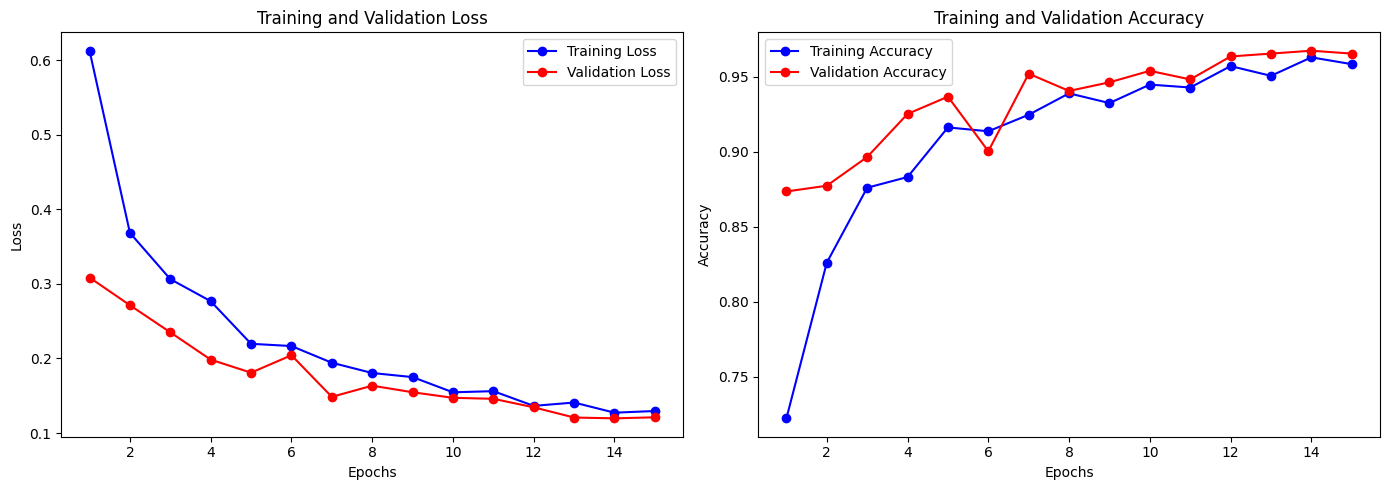

In [ ]:
# Curvas de treino/validacao (usa o history vivo deste fit).
viz.plot_training_history(history_resnet_phase1)


### 3.4 ResNet50 - Fine-Tuning

Partindo dos pesos obtidos na fase de Feature Extraction, procedemos ao Fine-Tuning
da ResNet50 seguindo a mesma metodologia aplicada à EfficientNetB0.

O *grid search* explorou 9 combinações de *learning rate* ∈ {1e-4, 1e-5, 1e-6} e
número de camadas descongeladas ∈ {10, 30, 50}, avaliadas pelo **F1-macro** na
validação.

A melhor combinação encontrada foi **LRPLACEHOLDER** com **CAMADAS DESCONGELADAS PLACEHOLDER** (F1=0.9682), sugerindo que um ajuste mais profundo da rede beneficia
a adaptação ao domínio oftalmológico.

In [ ]:
# ResNet50 — Fine-Tuning
# Guardar pesos da fase 1 antes de descongelar camadas.
# O grid search selecciona o melhor LR e número de camadas a descongelar.
phase1_weights_resnet = model_resnet.get_weights()

best_resnet = fine_tuning_grid_search(
    model_resnet,
    base_model_resnet,
    "ResNet50",
    phase1_weights_resnet
    )
history_resnet_ft = aplicar_melhor_fine_tuning(
    model_resnet,
    base_model_resnet,
    best_resnet,
    "ResNet50",
    phase1_weights_resnet
    )

=== ResNet50 | LR=0.0001  layers=10 ===
   F1-macro=0.9807  recall_catarata=0.9733
=== ResNet50 | LR=0.0001  layers=30 ===
   F1-macro=0.9778  recall_catarata=0.9733
=== ResNet50 | LR=0.0001  layers=50 ===
   F1-macro=0.9778  recall_catarata=0.9733
=== ResNet50 | LR=1e-05  layers=10 ===
   F1-macro=0.9650  recall_catarata=0.9733
=== ResNet50 | LR=1e-05  layers=30 ===
   F1-macro=0.9637  recall_catarata=0.9733
=== ResNet50 | LR=1e-05  layers=50 ===
   F1-macro=0.9638  recall_catarata=0.9733
=== ResNet50 | LR=1e-06  layers=10 ===
   F1-macro=0.9592  recall_catarata=0.9867
=== ResNet50 | LR=1e-06  layers=30 ===
   F1-macro=0.9054  recall_catarata=0.9733
=== ResNet50 | LR=1e-06  layers=50 ===
   F1-macro=0.9162  recall_catarata=0.9733

===== RANKING — ResNet50 =====
F1=0.9807  rec_cat=0.9733  <-  LR=0.0001  layers=10
F1=0.9778  rec_cat=0.9733  <-  LR=0.0001  layers=30
F1=0.9778  rec_cat=0.9733  <-  LR=0.0001  layers=50
F1=0.9650  rec_cat=0.9733  <-  LR=1e-05  layers=10
F1=0.9638  rec_cat=0

Última train accuracy: 1.0
Última val accuracy:   0.975095808506012
Melhor train accuracy: 1.0
Melhor val accuracy:   0.9808428883552551


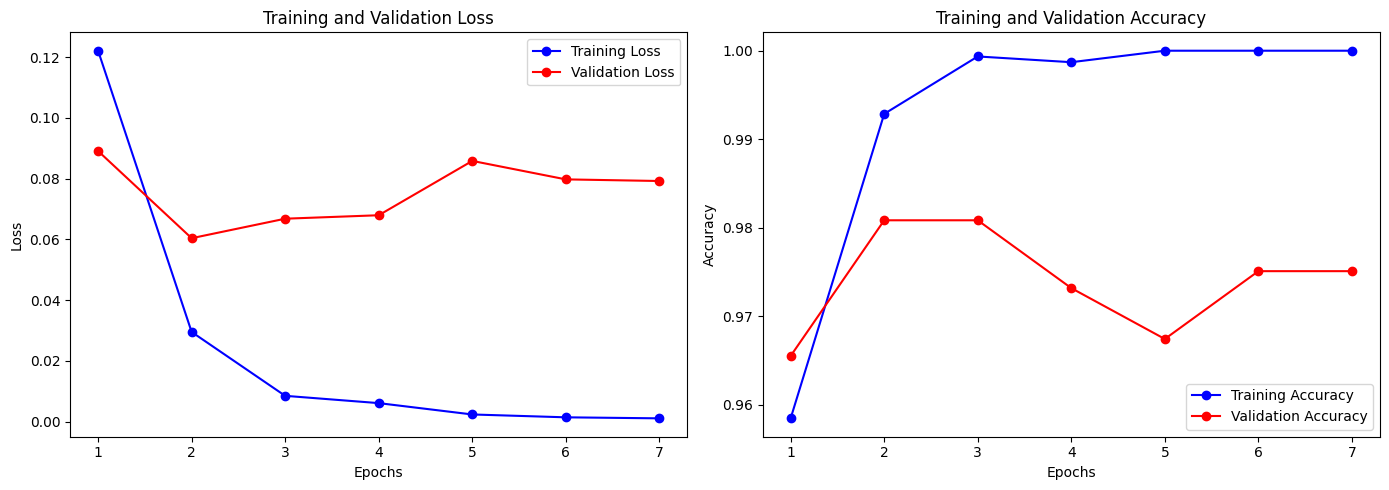

In [ ]:
# Curvas de treino/validacao (usa o history vivo deste fit).
viz.plot_training_history(history_resnet_ft)


## Diagnostico treino-vs-teste (modelos deste notebook)


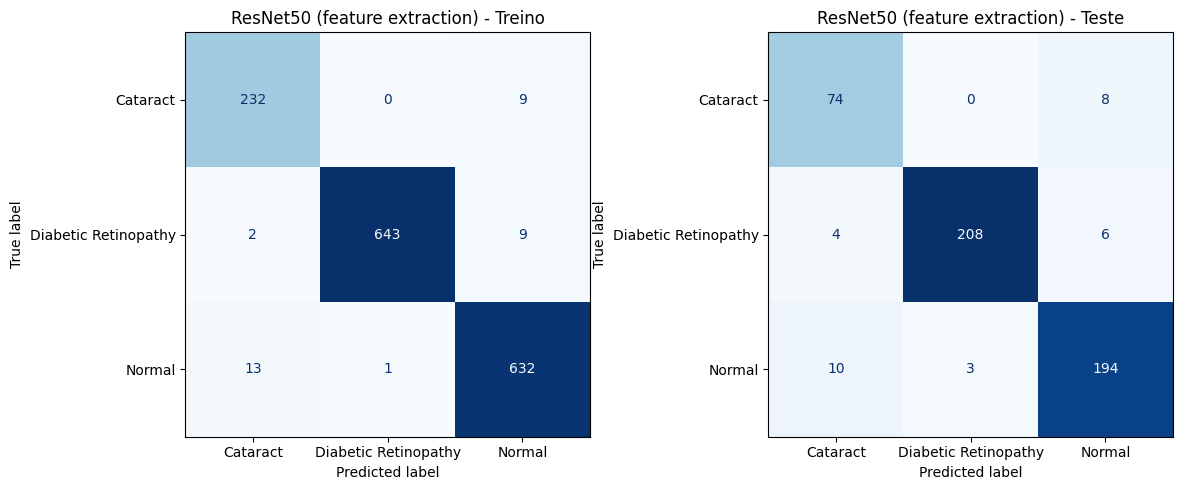

=== ResNet50 (feature extraction) | TREINO ===
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       241
           1       1.00      0.98      0.99       654
           2       0.97      0.98      0.98       646

    accuracy                           0.98      1541
   macro avg       0.97      0.97      0.97      1541
weighted avg       0.98      0.98      0.98      1541

=== ResNet50 (feature extraction) | TESTE ===
              precision    recall  f1-score   support

           0       0.84      0.90      0.87        82
           1       0.99      0.95      0.97       218
           2       0.93      0.94      0.93       207

    accuracy                           0.94       507
   macro avg       0.92      0.93      0.93       507
weighted avg       0.94      0.94      0.94       507




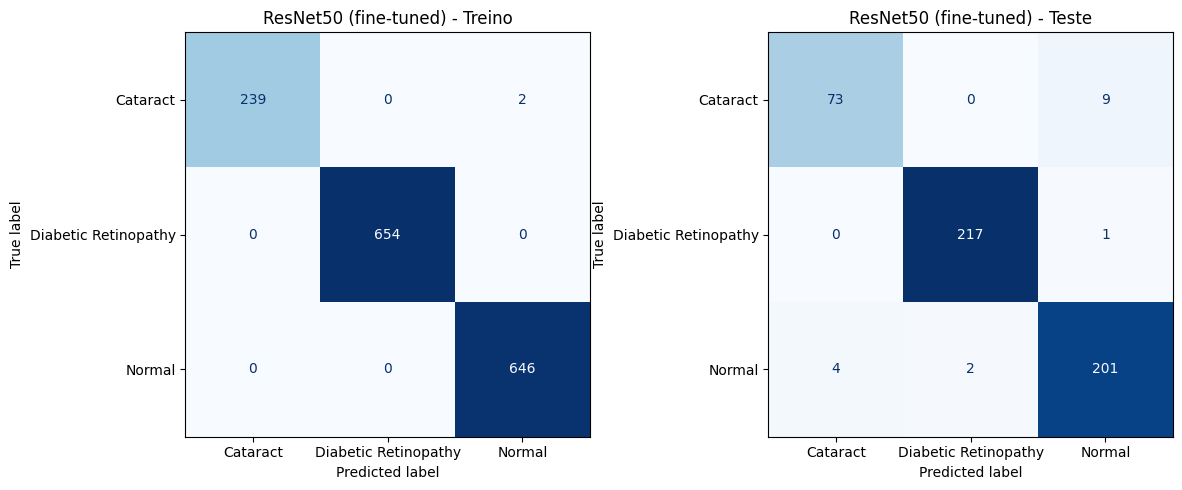

=== ResNet50 (fine-tuned) | TREINO ===
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       241
           1       1.00      1.00      1.00       654
           2       1.00      1.00      1.00       646

    accuracy                           1.00      1541
   macro avg       1.00      1.00      1.00      1541
weighted avg       1.00      1.00      1.00      1541

=== ResNet50 (fine-tuned) | TESTE ===
              precision    recall  f1-score   support

           0       0.95      0.89      0.92        82
           1       0.99      1.00      0.99       218
           2       0.95      0.97      0.96       207

    accuracy                           0.97       507
   macro avg       0.96      0.95      0.96       507
weighted avg       0.97      0.97      0.97       507



In [ ]:
# Diagnostico treino-vs-teste (overfitting) de cada modelo deste notebook, junto
# ao produtor -- onde as previsoes de treino (nao committed) ainda existem em
# memoria via modelos_treinados. Regenera output na proxima execucao.
for nome, modelo, history, X_t, X_tr, y_tr, proba_te, proba_tr in modelos_treinados:
    print("\n" + "="*55)
    viz.plot_train_test_confusion(proba_tr, y_tr, proba_te, y_test, class_names, nome_modelo=nome)


## Persistir metricas em `artifacts/results.csv`


In [ ]:
# Persistir a linha de cada modelo em artifacts/results.csv (upsert incremental
# -- 02/03/04 correm em sessoes separadas; a tabela e montada em disco e depois
# consumida por 05_clinical_evaluation).
for nome, modelo, history, X_t, X_tr, y_tr, proba_te, proba_tr in modelos_treinados:
    row = data.compute_metrics_row(nome, proba_te, y_test, class_names)
    data.append_results_row(row, ARTIFACTS_DIR / "results.csv")
print("results.csv atualizado.")


results.csv atualizado.
